# Instruction the lab-work #1
`TODO`: make the final .ipynb file in format `"{second_name}_{first_name}_{group_id}__lab_1.ipynb"`

First name     - Volodymyr

Second name    - Donets

Group          - KU-41

# Task description

## Overall description

In this lab work, you will get familiar with specific computer vision models for solving object detection (predicting Bounding Boxes / Regions of Interest), image segmentation (pixel-level classification), and gain practical experience with object tracking models across video frames. 

Additionally, you will train your own object detection model (from the YOLO family, MobileNet family, or similar) on a custom dataset using a standardized library.


## *Instructions for the work*

1. **Dataset Selection & Preparation**: Choose an image dataset that interests you (e.g., in YOLO or COCO format). Perform the necessary data preprocessing, augmentations, and split the data into training, validation, and test sets.
2. **Review Baselines**: Carefully study the provided examples to understand the standard computer vision pipeline, from loading images/videos to rendering predictions.
3. **Pre-trained Inference & Tracking**: Apply pre-trained models to perform zero-shot or out-of-the-box object detection, segmentation, and tracking on a sample video or set of images (use your own or look at prepared examples of data).
4. **Custom Model Training**: Fine-tune a lightweight object detection model (e.g., YOLOv10-nano, SSD MobileNet) on your selected dataset. Monitor training metrics like loss and mean Average Precision (mAP), Intersection over Union (IoU).
5. **Evaluation**: Analyze the results and write a conclusion. Compare the performance (mAP, IoU) and inference speed (FPS) of your custom-trained model against the pre-trained baseline.
6. 
## Examples

1. 

## Important

1. **No Single-Cell Solutions**: Do NOT write all your code in a single Jupyter Notebook cell. Your code must be logically separated. Single-cell notebooks will receive a grade of 0. If you need help structuring a notebook, ask the instructor or your peers. Alternatively, you may submit well-structured .py files alongside a .pdf report of your results.
2. **Academic Integrity**: Plagiarism is prohibited. Identical or copied works will automatically receive a grade of 0.
3. **Submission Format**: You are encouraged to solve this assignment in a separate .ipynb file. You may duplicate the provided template, clear the existing solution, and build your own.
4. **Mandatory Conclusions**: A project without a written analytical conclusion is incomplete. Do not forget to summarize your findings at the end of your notebook.

## How to get max num of points without personal work presentation.

As I told you, you can get the maximum mark for all lab works without personal presentation in case of using something different and additional depth of work.
So for this work you can:

1. `Track A`: Compare the performance of tiny and large object detection models, or compare fundamentally different architectures (e.g., YOLO vs. Faster R-CNN) trained on your data.
2. `Track B`: Gather and annotate your own custom data (non-Kaggle). For example, creating a dataset to detect your own socks, your pets, or specific items on your desk.
3. `Track C`: Implement real-time inference or deployment. Run your trained model in real-time using your computer's webcam, or wrap the model in a simple local web interface (using Gradio or Streamlit) where a user can upload an image and get predictions.

# 1. Import dependencies

In [1]:
# Install required dependencies
%pip install opencv-python matplotlib numpy pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Set plotting style for clear visualizations
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['image.interpolation'] = 'nearest'

# 2. Tool functions

In [3]:
def load_image(image_path: str) -> np.ndarray:
    """
    Load an image from disk and convert BGR (OpenCV default) to RGB.
    """
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise FileNotFoundError(f"Image not found at path: {image_path}")
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    return img_rgb


def draw_bounding_boxes(
    image: np.ndarray,
    boxes: list,
    color: tuple = (255, 0, 0),
    thickness: int = 2,
    label: str = None
) -> np.ndarray:
    """
    Draw bounding boxes on a copy of the RGB image.
    Each box is in format (x, y, w, h).
    """
    img_copy = image.copy()
    for (x, y, w, h) in boxes:
        cv2.rectangle(img_copy, (x, y), (x + w, y + h), color, thickness)
        if label:
            label_size, _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1)
            cv2.rectangle(
                img_copy,
                (x, max(0, y - label_size[1] - 8)),
                (x + label_size[0] + 4, max(0, y)),
                color,
                -1
            )
            cv2.putText(
                img_copy,
                label,
                (x + 2, max(label_size[1] + 2, y - 4)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 255, 255),
                1,
                cv2.LINE_AA
            )
    return img_copy


def visualize_detections(
    original_img: np.ndarray,
    detected_img: np.ndarray,
    title: str = "Detection Result"
):
    """
    Display original and detected images side-by-side.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(original_img)
    axes[0].set_title("Original Image", fontsize=14)
    axes[0].axis("off")

    axes[1].imshow(detected_img)
    axes[1].set_title(title, fontsize=14)
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

In [4]:
# Configure source folder for human ROI test images
DATA_DIR = os.path.join("src", "human_ROI_test")
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join("lab_works_2026_2027_1st_sem", "lab_1", "src", "human_ROI_test")

image_extensions = ("*.jpg", "*.jpeg", "*.png")

# Collect all available test images in source folder
image_paths = []
for ext in image_extensions:
    image_paths.extend(glob.glob(os.path.join(DATA_DIR, ext)))
image_paths = sorted(image_paths)

print(f"Found {len(image_paths)} images in '{DATA_DIR}':")
for p in image_paths:
    print(f" - {os.path.basename(p)}")

Found 7 images in 'src\human_ROI_test':
 - couple_1.jpg
 - couple_2.jpg
 - crowd_1.jpg
 - crowd_2.jpg
 - crowd_3.jpg
 - man_1.jpg
 - man_2.jpg


# 3. Running object detection models (ROI detection)

## 3.1. HaaR Cascades -- object detection method from classical ML era

In [5]:
# Load pre-trained Haar cascade models from OpenCV data directory
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_eye.xml")
fullbody_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_fullbody.xml")
upperbody_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_upperbody.xml")

print("Haar Cascade Classifiers loaded successfully:")
print(" - Frontal Face:", not face_cascade.empty())
print(" - Eyes:", not eye_cascade.empty())
print(" - Full Body:", not fullbody_cascade.empty())
print(" - Upper Body:", not upperbody_cascade.empty())


def detect_haar_objects(
    image: np.ndarray,
    detect_faces: bool = True,
    detect_eyes: bool = True,
    detect_fullbody: bool = False,
    detect_upperbody: bool = False,
    scale_factor: float = 1.1,
    min_neighbors: int = 5,
    min_size: tuple = (30, 30)
) -> tuple[np.ndarray, dict]:
    """
    Perform Haar Cascade detection on RGB image and return annotated image and detection coordinates.
    """
    result_img = image.copy()
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    detections = {}

    if detect_fullbody:
        bodies = fullbody_cascade.detectMultiScale(
            gray, scaleFactor=1.05, minNeighbors=3, minSize=(50, 100)
        )
        detections['fullbody'] = bodies
        result_img = draw_bounding_boxes(result_img, bodies, color=(0, 255, 0), thickness=2, label="Body")

    if detect_upperbody:
        upper_bodies = upperbody_cascade.detectMultiScale(
            gray, scaleFactor=1.05, minNeighbors=3, minSize=(50, 50)
        )
        detections['upperbody'] = upper_bodies
        result_img = draw_bounding_boxes(result_img, upper_bodies, color=(255, 165, 0), thickness=2, label="UpperBody")

    if detect_faces:
        faces = face_cascade.detectMultiScale(
            gray, scaleFactor=scale_factor, minNeighbors=min_neighbors, minSize=min_size
        )
        detections['faces'] = faces
        result_img = draw_bounding_boxes(result_img, faces, color=(255, 0, 0), thickness=2, label="Face")

        if detect_eyes:
            for (fx, fy, fw, fh) in faces:
                roi_gray = gray[fy:fy+fh, fx:fx+fw]
                roi_color = result_img[fy:fy+fh, fx:fx+fw]
                eyes = eye_cascade.detectMultiScale(roi_gray, scaleFactor=1.1, minNeighbors=4, minSize=(15, 15))
                for (ex, ey, ew, eh) in eyes:
                    cv2.rectangle(roi_color, (ex, ey), (ex + ew, ey + eh), (0, 255, 255), 2)
                    cv2.putText(roi_color, "Eye", (ex, max(ey - 2, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 255), 1)

    return result_img, detections

Haar Cascade Classifiers loaded successfully:
 - Frontal Face: True
 - Eyes: True
 - Full Body: True
 - Upper Body: True


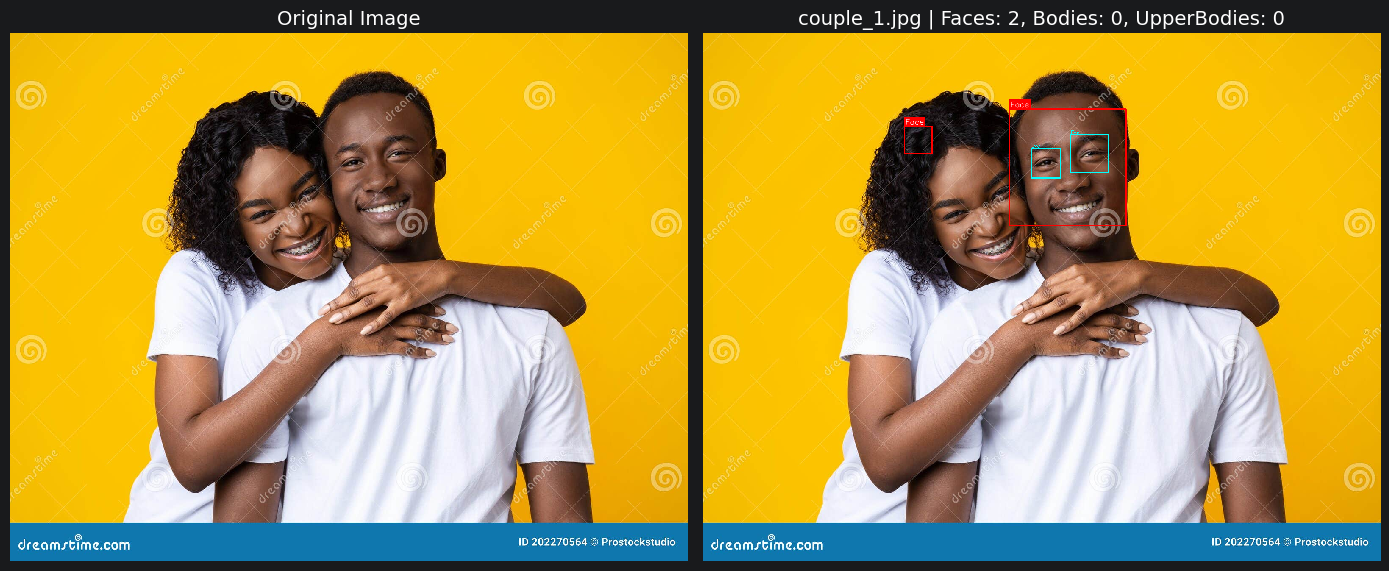

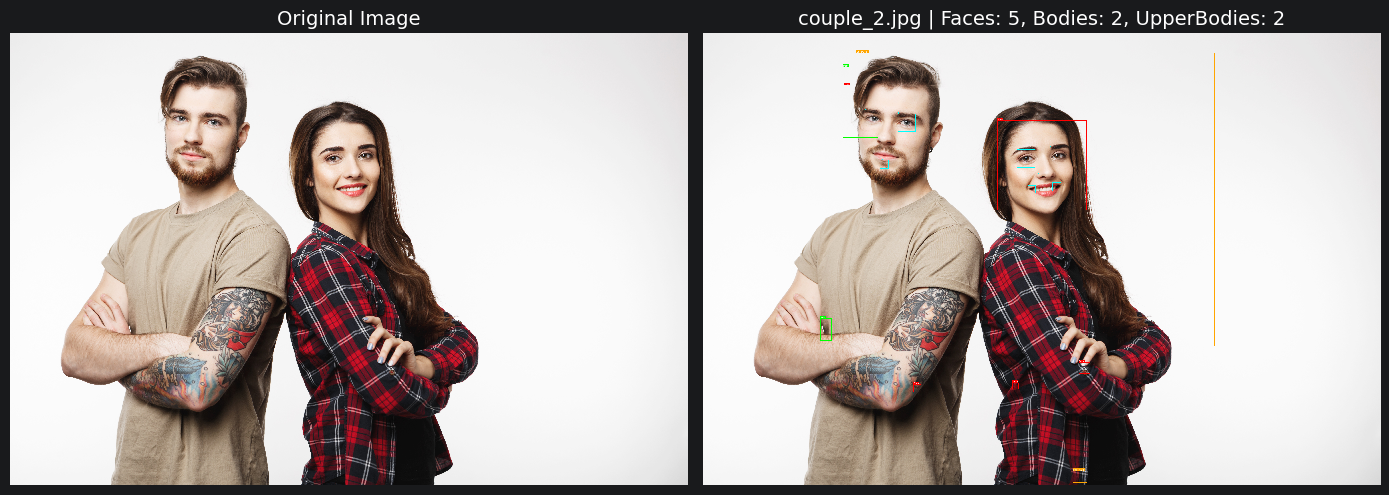

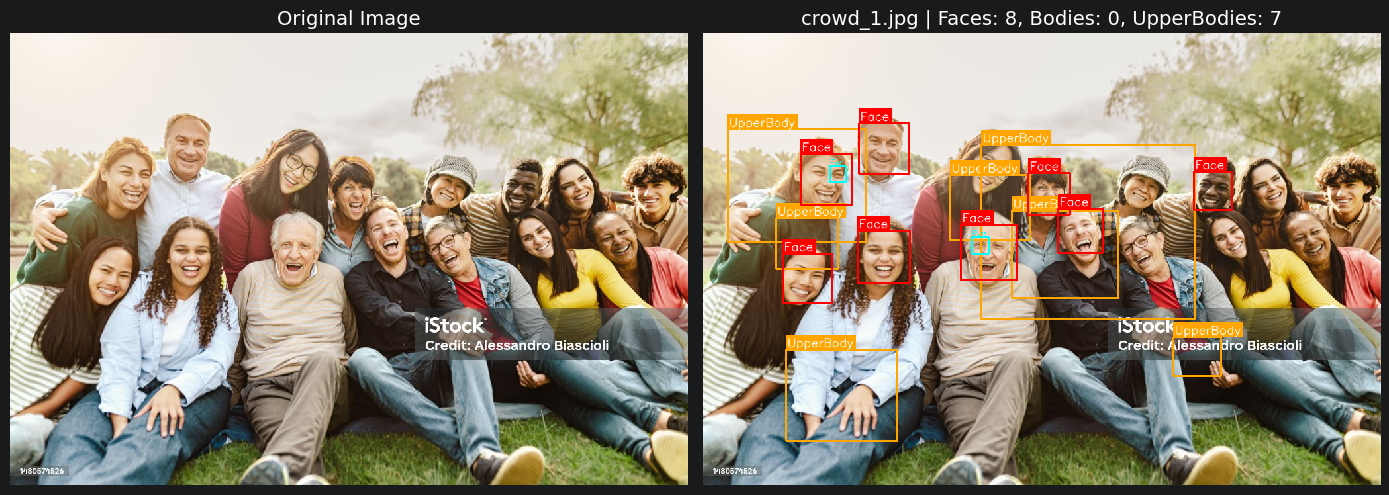

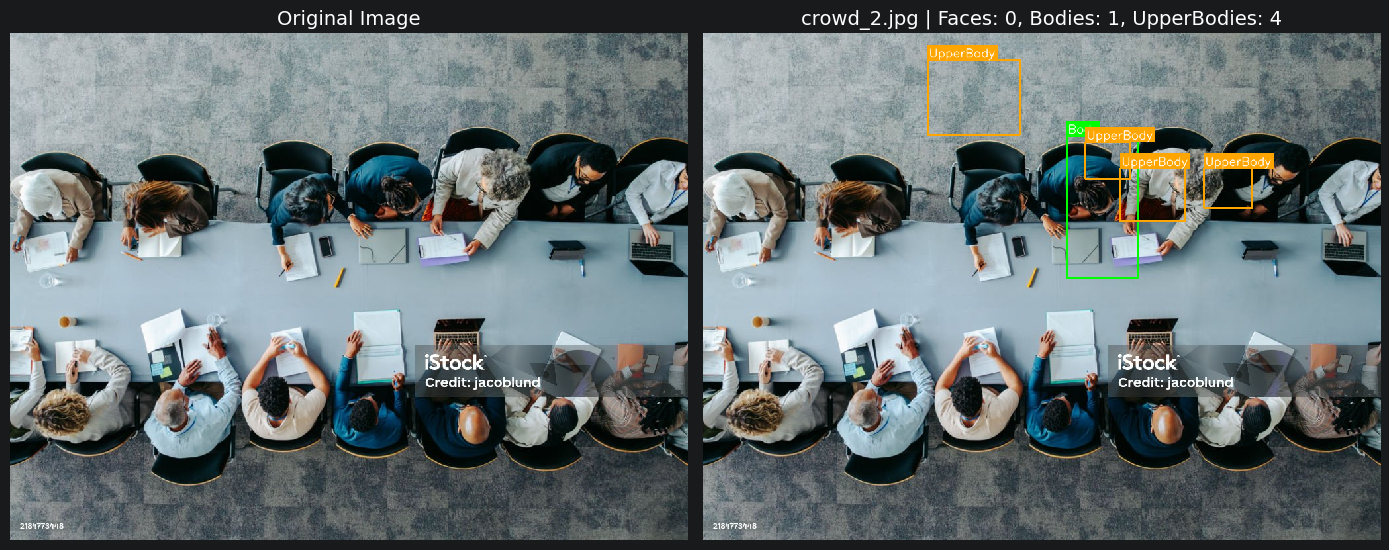

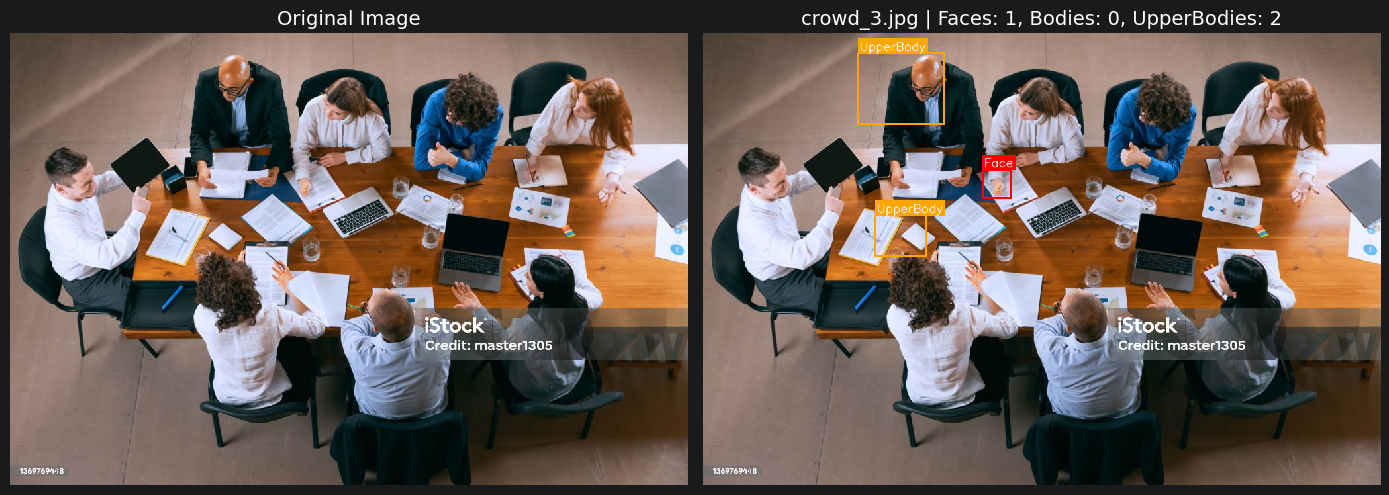

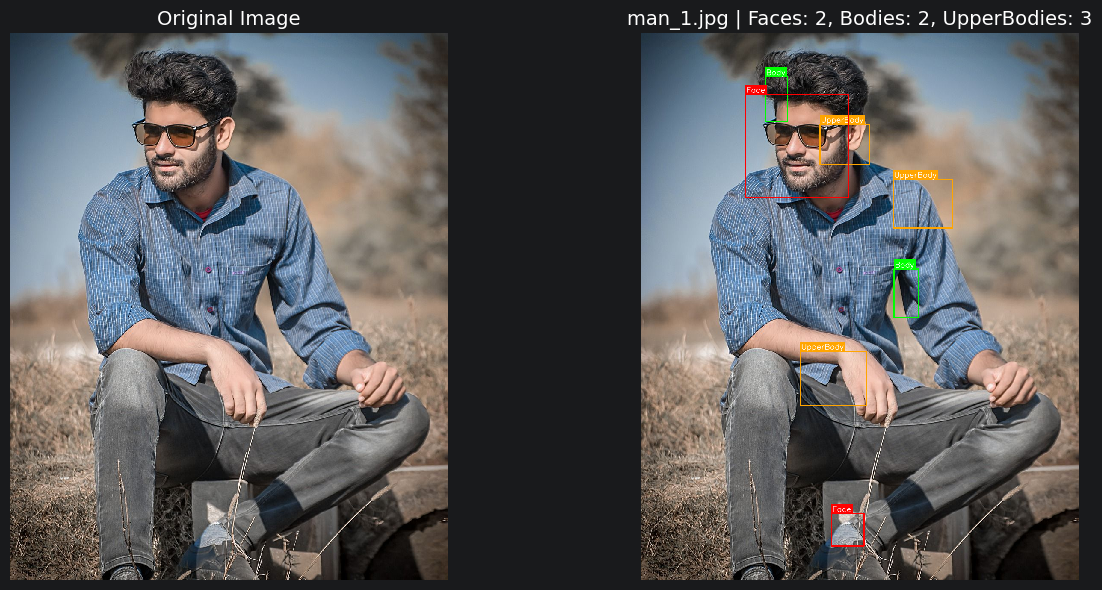

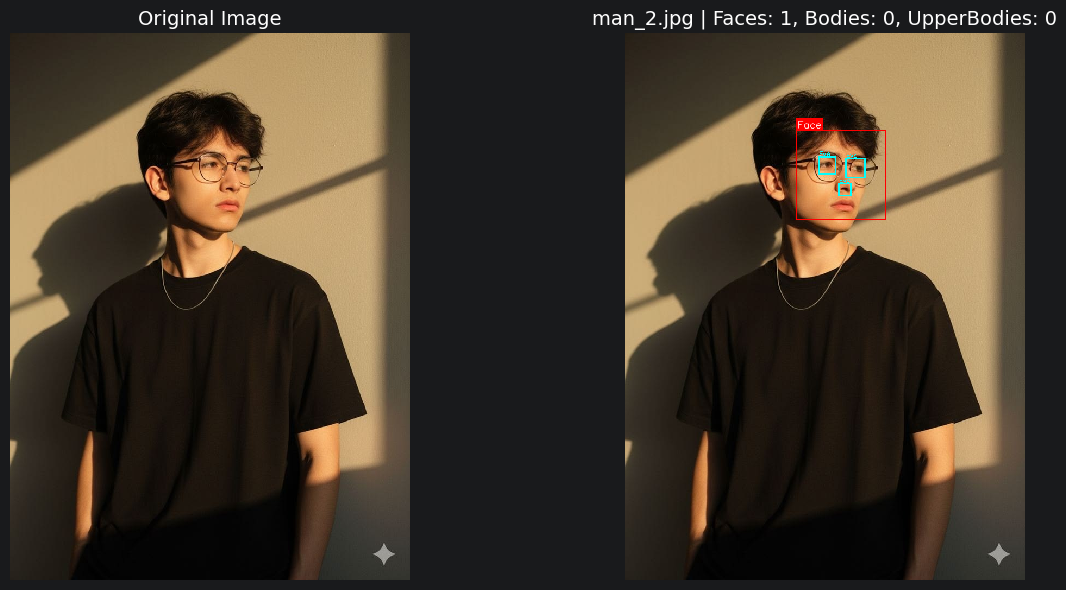

In [6]:
# Visualize Haar Cascade detection results across test images from human_ROI_test
for img_path in image_paths:
    img_name = os.path.basename(img_path)
    img = load_image(img_path)

    # Run detection: faces, eyes, and full body / upper body
    detected_img, detections = detect_haar_objects(
        img,
        detect_faces=True,
        detect_eyes=True,
        detect_fullbody=True,
        detect_upperbody=True,
        scale_factor=1.1,
        min_neighbors=5,
        min_size=(30, 30)
    )

    num_faces = len(detections.get('faces', []))
    num_bodies = len(detections.get('fullbody', []))
    num_upper = len(detections.get('upperbody', []))

    title = f"{img_name} | Faces: {num_faces}, Bodies: {num_bodies}, UpperBodies: {num_upper}"
    visualize_detections(img, detected_img, title=title)

## 3.2. YOLOv10 tiny (trained on COCO dataset)

* [HugginFace model source](https://huggingface.co/jameslahm/yolov10n)
* [Git Repo of the Devs](https://github.com/THU-MIG/yolov10)
* [Article](https://arxiv.org/abs/2405.14458)

## 3.3. MobileNetV3 (trained on COCO dataset)




# 4. Running segmentation models (coloring image pixels with it's corresponding class)

# 5. Running object tracking models

# 6. Combining models 
(Movement identification with MOG2 -> Object detection -> Object tracking)